# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <StringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


## Task 1 - A line chart showing CO2 per Capita for all countries in the dataset

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

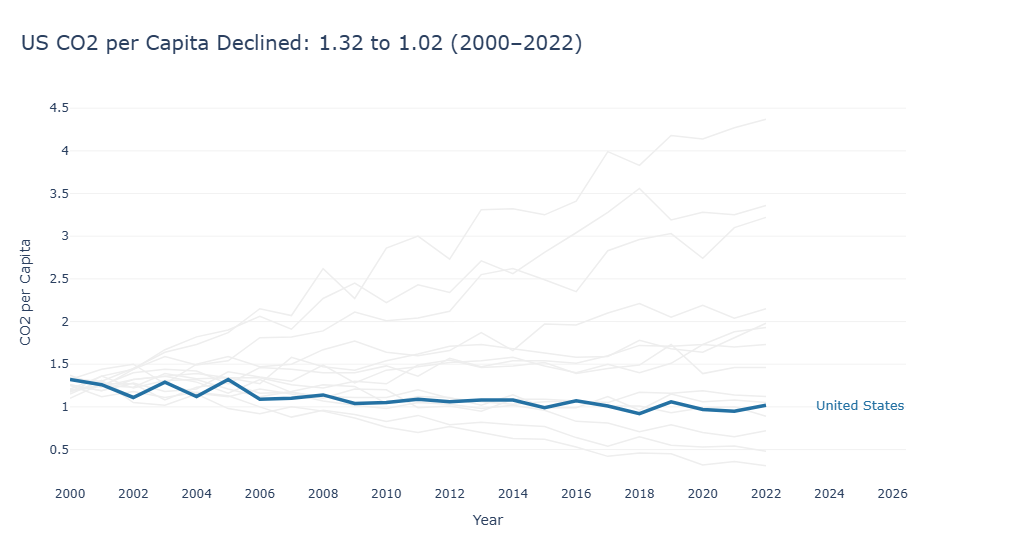

In [3]:
# Task 1: CO2 per capita for all countries
# Highlight the United States

import plotly.graph_objects as go

# Step 1: Choose the country to highlight
highlight_country = 'United States'

# Step 2: Sort the data by year for each country
df_sorted = df.sort_values('Year')

# Get the highlighted country's data
highlight_df = df_sorted[
    df_sorted['Country'] == highlight_country
].sort_values('Year')

# Calculate the change from the first year to the last year
start_value = highlight_df.iloc[0]['CO2_per_capita']
end_value = highlight_df.iloc[-1]['CO2_per_capita']
start_year = int(highlight_df.iloc[0]['Year'])
end_year = int(highlight_df.iloc[-1]['Year'])

if end_value < start_value:
    trend = 'declined'
elif end_value > start_value:
    trend = 'increased'
else:
    trend = 'remained stable'

# Step 3: Create the figure
fig = go.Figure()

# Add all countries in light grey
for country in df_sorted['Country'].unique():
    if country != highlight_country:
        country_df = df_sorted[df_sorted['Country'] == country]

        fig.add_trace(go.Scatter(
            x=country_df['Year'],
            y=country_df['CO2_per_capita'],
            mode='lines',
            name=country,
            line=dict(color='#EEEEEE', width=1.5),
            hovertemplate=(
                f'{country}<br>'
                'Year: %{x}<br>'
                'CO2 per capita: %{y:.2f}'
                '<extra></extra>'
            ),
            showlegend=False
        ))

# Add the United States as the highlighted line
fig.add_trace(go.Scatter(
    x=highlight_df['Year'],
    y=highlight_df['CO2_per_capita'],
    mode='lines',
    name=highlight_country,
    line=dict(color='#2471A3', width=3.5),
    hovertemplate=(
        'United States<br>'
        'Year: %{x}<br>'
        'CO2 per capita: %{y:.2f}'
        '<extra></extra>'
    ),
    showlegend=False
))

# Step 4: Label the highlighted line at its endpoint
fig.add_annotation(
    x=end_year,
    y=end_value,
    text='United States',
    showarrow=False,
    xshift=48,
    font=dict(size=13, color='#2471A3'),
    xanchor='left'
)

# Step 5: Add an insight title
fig.update_layout(
    title=(
        f'US CO2 per Capita {trend.capitalize()}: '
        f'{start_value:.2f} to {end_value:.2f} '
        f'({start_year}–{end_year})'
    ),
    template='plotly_white',
    title_x=0.02,
    title_font_size=20,
    height=550,
    margin=dict(l=70, r=130, t=100, b=65),
    xaxis_title='Year',
    yaxis_title='CO2 per Capita',
    showlegend=False,
    hovermode='x unified'
)

# Remove chart borders and heavy gridlines
fig.update_xaxes(
    showline=False,
    showgrid=False,
    zeroline=False,
    dtick=2
)

fig.update_yaxes(
    showline=False,
    showgrid=True,
    gridcolor='#F2F2F2',
    zeroline=False
)

fig.show()

---
## Task 2 — A line chart showing CO2 emissions over time for all Asian countries in the dataset, with one country highlighted.

**same requirements as Task1**

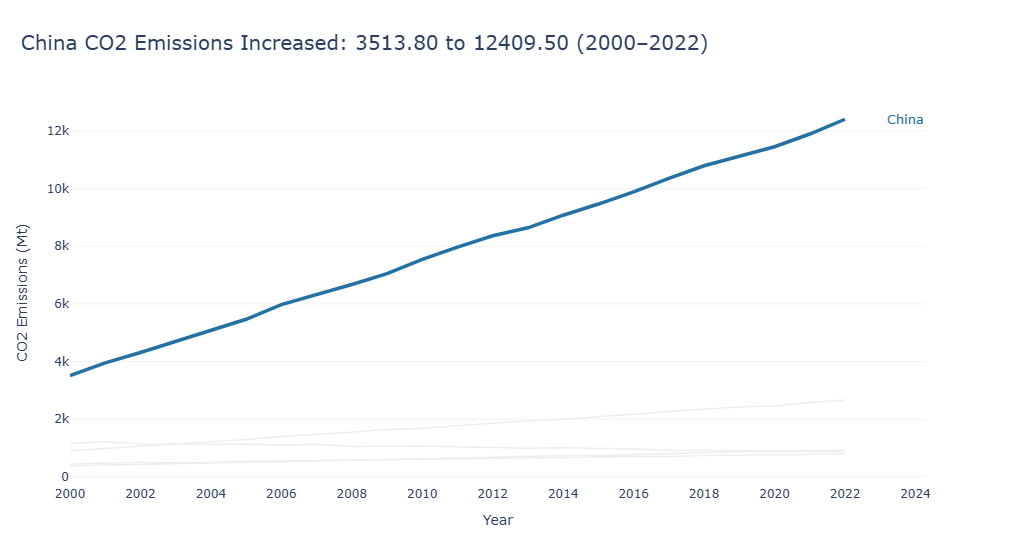

In [4]:
# Task — Multi-series line with highlight
# YOUR CODE HERE

# Task 2: CO2 emissions over time for Asian countries
# Highlight China

import plotly.graph_objects as go

highlight_country = 'China'

# Filter the dataset to Asian countries only
asia_df = df[df['Region'].str.contains('Asia', case=False, na=False)].copy()
asia_df = asia_df.sort_values('Year')

# Separate China from the other Asian countries
highlight_df = asia_df[
    asia_df['Country'] == highlight_country
].sort_values('Year')

if highlight_df.empty:
    print("China was not found in the Asian countries dataset.")
else:
    start_value = highlight_df.iloc[0]['CO2_Mt']
    end_value = highlight_df.iloc[-1]['CO2_Mt']
    start_year = int(highlight_df.iloc[0]['Year'])
    end_year = int(highlight_df.iloc[-1]['Year'])

    if end_value < start_value:
        trend = 'declined'
    elif end_value > start_value:
        trend = 'increased'
    else:
        trend = 'remained stable'

    fig = go.Figure()

    # Draw all other Asian countries in light grey
    for country in asia_df['Country'].unique():
        if country != highlight_country:
            country_df = asia_df[
                asia_df['Country'] == country
            ].sort_values('Year')

            fig.add_trace(go.Scatter(
                x=country_df['Year'],
                y=country_df['CO2_Mt'],
                mode='lines',
                line=dict(color='#EEEEEE', width=1.5),
                name=country,
                showlegend=False,
                hovertemplate=(
                    f'{country}<br>'
                    'Year: %{x}<br>'
                    'CO2 emissions: %{y:.2f}'
                    '<extra></extra>'
                )
            ))

    # Draw China in blue
    fig.add_trace(go.Scatter(
        x=highlight_df['Year'],
        y=highlight_df['CO2_Mt'],
        mode='lines',
        line=dict(color='#2471A3', width=3.5),
        name=highlight_country,
        showlegend=False,
        hovertemplate=(
            'China<br>'
            'Year: %{x}<br>'
            'CO2 emissions: %{y:.2f}'
            '<extra></extra>'
        )
    ))

    # Label China at the end of its line
    fig.add_annotation(
        x=end_year,
        y=end_value,
        text='China',
        showarrow=False,
        xshift=40,
        xanchor='left',
        font=dict(size=13, color='#2471A3')
    )

    fig.update_layout(
        title=(
            f'China CO2 Emissions {trend.capitalize()}: '
            f'{start_value:.2f} to {end_value:.2f} '
            f'({start_year}–{end_year})'
        ),
        template='plotly_white',
        title_x=0.02,
        title_font_size=20,
        height=550,
        margin=dict(l=70, r=110, t=100, b=65),
        xaxis_title='Year',
        yaxis_title='CO2 Emissions (Mt)',
        showlegend=False,
        hovermode='x unified'
    )

    fig.update_xaxes(
        showline=False, showgrid=False,
        zeroline=False, dtick=2
    )
    fig.update_yaxes(
        showline=False, showgrid=True,
        gridcolor='#F2F2F2', zeroline=False
    )

    fig.show()
